# AAI-521 Final Team Project: Automated Pollinator Insect Classification & Feature Engineering
**Dataset:** phucthaiv02/butterfly-image-classification (Kaggle)

## Project Set-Up

In [1]:
# Install required dependencies including kagglehub
!pip install -q kagglehub albumentations opencv-python-headless tqdm pyarrow scikit-learn

import hashlib
import json
import os
import random
import shutil
import warnings
import zipfile
from pathlib import Path
from typing import Dict, List, Tuple
import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2
from google.colab import drive
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import seaborn as sns
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import DataLoader, Dataset
from tqdm.notebook import tqdm

warnings.filterwarnings("ignore")

In [2]:
# Set random seeds for reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

# Configure Matplotlib style for publication-ready Technical Report figures (APA 7 compatible)
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 150
sns.set_theme(style="whitegrid", palette="viridis")

# Mount Google Drive and configure persistent output directories
drive.mount("/content/drive", force_remount=False)

drive_project_root = Path(
    "/content/drive/MyDrive/Colab Notebooks/AAI521_Pollinator_Project"
)
preprocessed_dir = drive_project_root / "preprocessed_data"
plots_dir = drive_project_root / "eda_figures"
metadata_out_dir = drive_project_root / "processed_metadata"

for directory in [drive_project_root, preprocessed_dir, plots_dir, metadata_out_dir]:
    directory.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


## Repository and Dataset Validation

In [3]:
kaggle_dataset_id = "phucthaiv02/butterfly-image-classification"
dataset_path = Path(kagglehub.dataset_download(kaggle_dataset_id))

# Extract any zipped archives
for zip_file in dataset_path.rglob("*.zip"):
    extract_target = dataset_path / "extracted"
    if not extract_target.exists():
        print(f"Extracting archive: {zip_file.name}...")
        with zipfile.ZipFile(zip_file, "r") as zip_ref:
            zip_ref.extractall(extract_target)

# Training_set.csv containing ground-truth filenames and 75 butterfly species labels
train_csv_matches = list(dataset_path.rglob("Training_set.csv"))
if not train_csv_matches:
    raise FileNotFoundError(f"Could not find Training_set.csv in {dataset_path}")

train_csv_path = train_csv_matches[0]
raw_labels_df = pd.read_csv(train_csv_path)
raw_labels_df.columns = [c.strip().lower() for c in raw_labels_df.columns]
filename_col = "filename" if "filename" in raw_labels_df.columns else raw_labels_df.columns[0]
species_col = "label" if "label" in raw_labels_df.columns else raw_labels_df.columns[1]

# Build a lookup dictionary of physical image files in the train folder
disk_images = {}
for img_p in dataset_path.rglob("*"):
    if img_p.is_file() and img_p.suffix.lower() in (".jpg", ".jpeg", ".png"):
        if "train" in str(img_p.parent).lower() or img_p.name not in disk_images:
            disk_images[img_p.name] = img_p

# Check file existence
valid_records = []
corrupted_files = []

for idx, row in tqdm(raw_labels_df.iterrows(), total=len(raw_labels_df), desc="DL Readiness Audit"):
    fname = str(row[filename_col]).strip()
    species_name = str(row[species_col]).strip().upper()
    candidate_path = disk_images.get(fname)

    if candidate_path is None or not candidate_path.exists():
        corrupted_files.append((fname, "Missing File"))
        continue

    try:
        file_bytes = candidate_path.read_bytes()
        md5_hash = hashlib.md5(file_bytes).hexdigest()

        with Image.open(candidate_path) as img:
            img = ImageOps.exif_transpose(img)
            img.load()
            width, height = img.size
            mode = img.mode

        valid_records.append({
            "image_id": candidate_path.stem,
            "filename": fname,
            "class_name": species_name,
            "local_full_path": str(candidate_path),
            "file_hash": md5_hash,
            "verified_width": width,
            "verified_height": height,
            "verified_mode": mode,
            "verified_aspect_ratio": round(width / max(height, 1), 4),
        })
    except Exception as e:
        corrupted_files.append((fname, str(e)))

df_clean = pd.DataFrame(valid_records)

# Deduplicate identical images
before_dedup = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=["file_hash"], keep="first").reset_index(drop=True)
duplicates_removed = before_dedup - len(df_clean)

# Map species names to integer class IDs
sorted_species = sorted(df_clean["class_name"].unique())
species_to_idx = {name: idx for idx, name in enumerate(sorted_species)}
df_clean["label"] = df_clean["class_name"].map(species_to_idx)

# Save taxonomic mapping JSON to google drive
with open(metadata_out_dir / "class_info.json", "w", encoding="utf-8") as f:
    json.dump({str(idx): name for name, idx in species_to_idx.items()}, f, indent=4)

# Perform splits
train_idx, temp_idx = train_test_split(
    df_clean.index,
    test_size=0.20,
    random_state=seed,
    stratify=df_clean["label"],
)
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=seed,
    stratify=df_clean.loc[temp_idx, "label"],
)

df_clean["split"] = "train"
df_clean.loc[val_idx, "split"] = "validation"
df_clean.loc[test_idx, "split"] = "test"

# Verify zero cross-split hash leakage
train_hashes = set(df_clean[df_clean["split"] == "train"]["file_hash"])
val_hashes = set(df_clean[df_clean["split"] == "validation"]["file_hash"])
test_hashes = set(df_clean[df_clean["split"] == "test"]["file_hash"])

print(f"Total Labeled Records in CSV    {len(raw_labels_df):,}")
print(f"Duplicate Hashes Removed        {duplicates_removed:,}")
print(f"Verified Unique Valid Images    {len(df_clean):,}")
print(f"Corrupted or Missing Images     {len(corrupted_files):,}")
print(f"Number of Butterfly Species     {df_clean['label'].nunique()}")
print(f"Color Modes Present             {df_clean['verified_mode'].value_counts().to_dict()}")
print(f"Stratified Split Counts         {df_clean['split'].value_counts().to_dict()}")
print(
    f"Cross-Split Hash Leakage Check  "
    f"Train-Val={len(train_hashes & val_hashes)}, "
    f"Train-Test={len(train_hashes & test_hashes)}, "
    f"Val-Test={len(val_hashes & test_hashes)}"
)

Using Colab cache for faster access to the 'butterfly-image-classification' dataset.


DL Readiness Audit:   0%|          | 0/6499 [00:00<?, ?it/s]

Total Labeled Records in CSV    6,499
Duplicate Hashes Removed        4
Verified Unique Valid Images    6,495
Corrupted or Missing Images     0
Number of Butterfly Species     75
Color Modes Present             {'RGB': 6495}
Stratified Split Counts         {'train': 5196, 'test': 650, 'validation': 649}
Cross-Split Hash Leakage Check  Train-Val=0, Train-Test=0, Val-Test=0


## Exploratory Data Analysis

Summary results:



split,label,class_name,test,train,validation,Total
0,45,MOURNING CLOAK,13,105,13,131
1,64,SLEEPY ORANGE,11,86,10,107
2,5,ATALA,10,80,10,100
3,12,BROWN SIPROETA,10,79,10,99
4,23,CRECENT,10,78,9,97
5,6,BANDED ORANGE HELICONIAN,10,78,9,97
6,62,SCARCE SWALLOW,10,78,9,97
7,47,ORANGE TIP,10,77,9,96
8,59,RED CRACKER,10,77,9,96
9,43,MILBERTS TORTOISESHELL,10,77,9,96



Image Dimensions and Aspect Ratio Summary:



,verified_width,verified_height,verified_aspect_ratio
count,6495.0,6495.0,6495.0
mean,224.0,224.0,1.0
std,0.0,0.0,0.0
min,224.0,224.0,1.0
25%,224.0,224.0,1.0
50%,224.0,224.0,1.0
75%,224.0,224.0,1.0
max,224.0,224.0,1.0


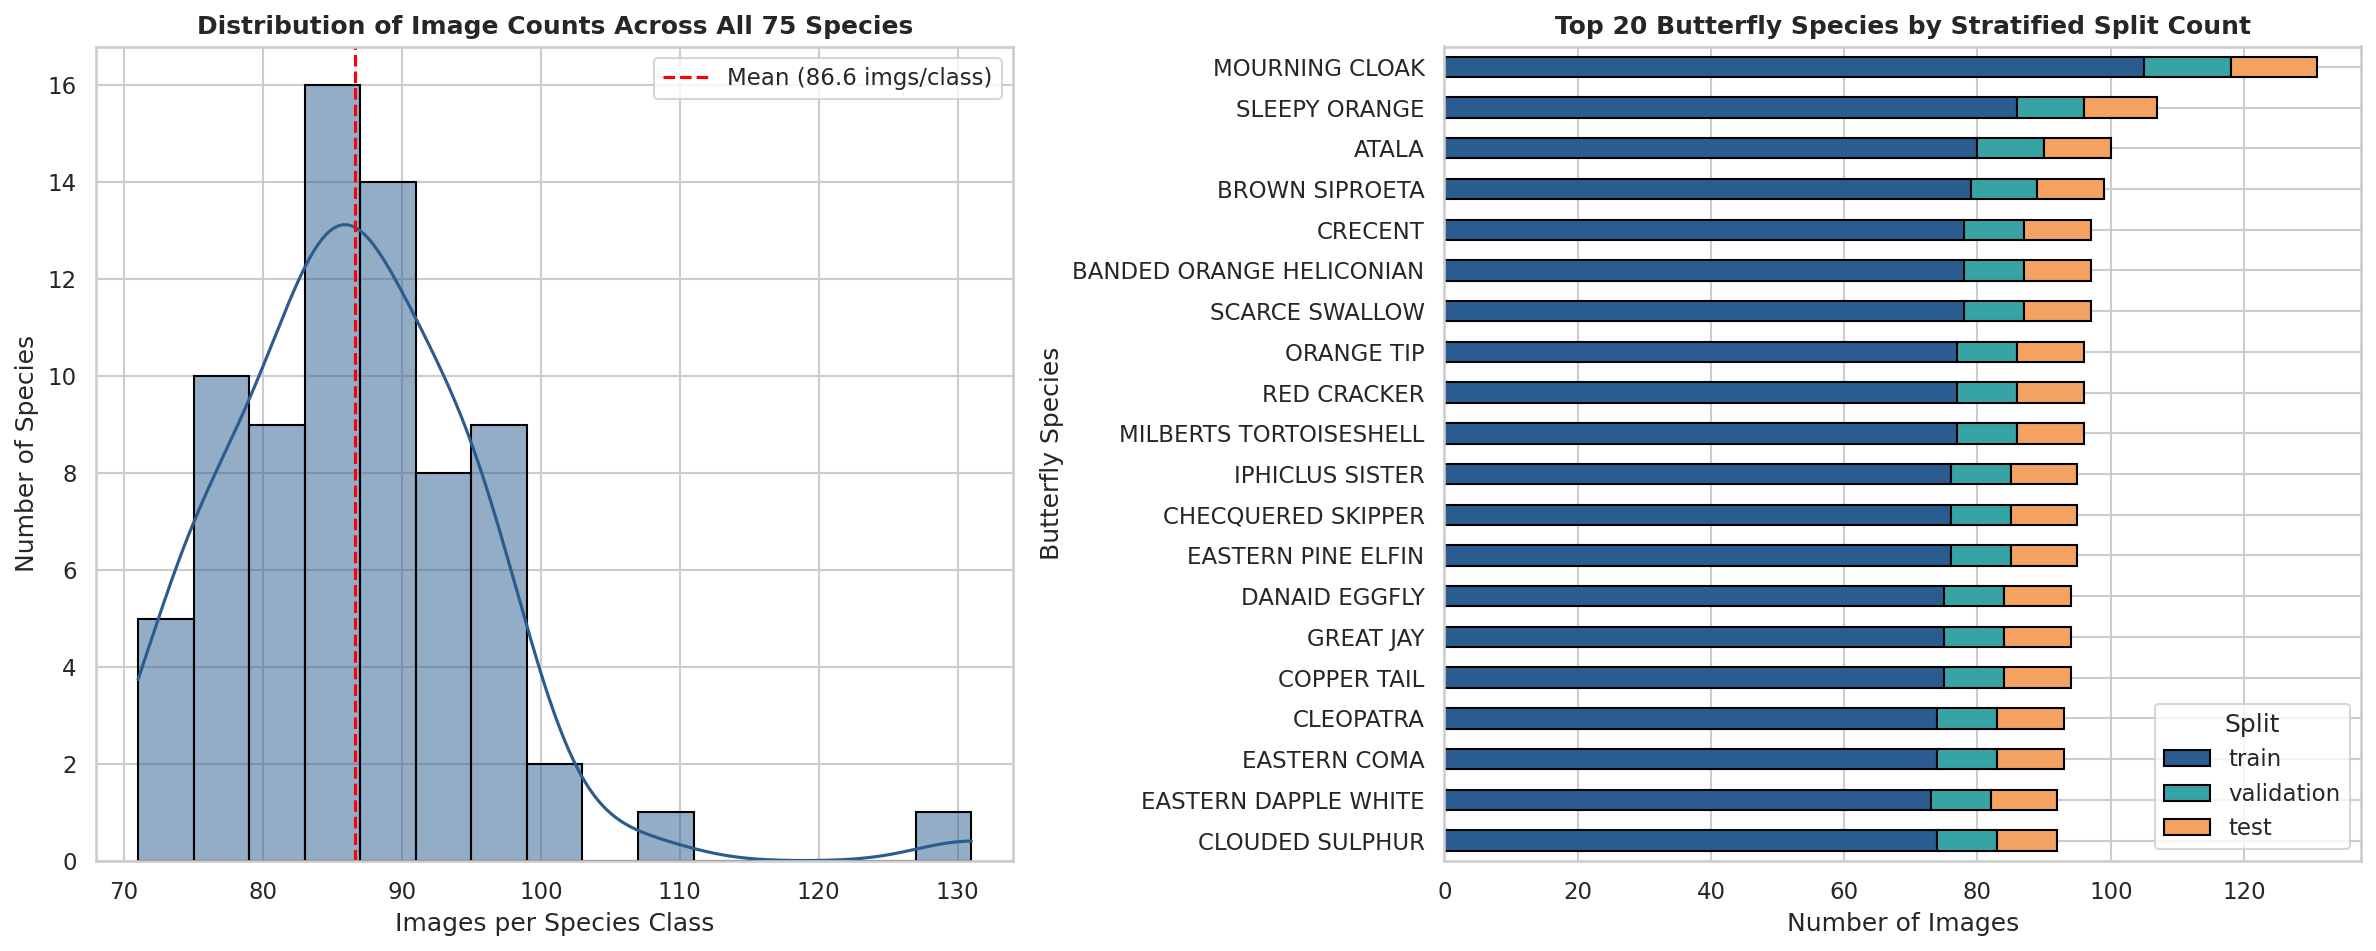

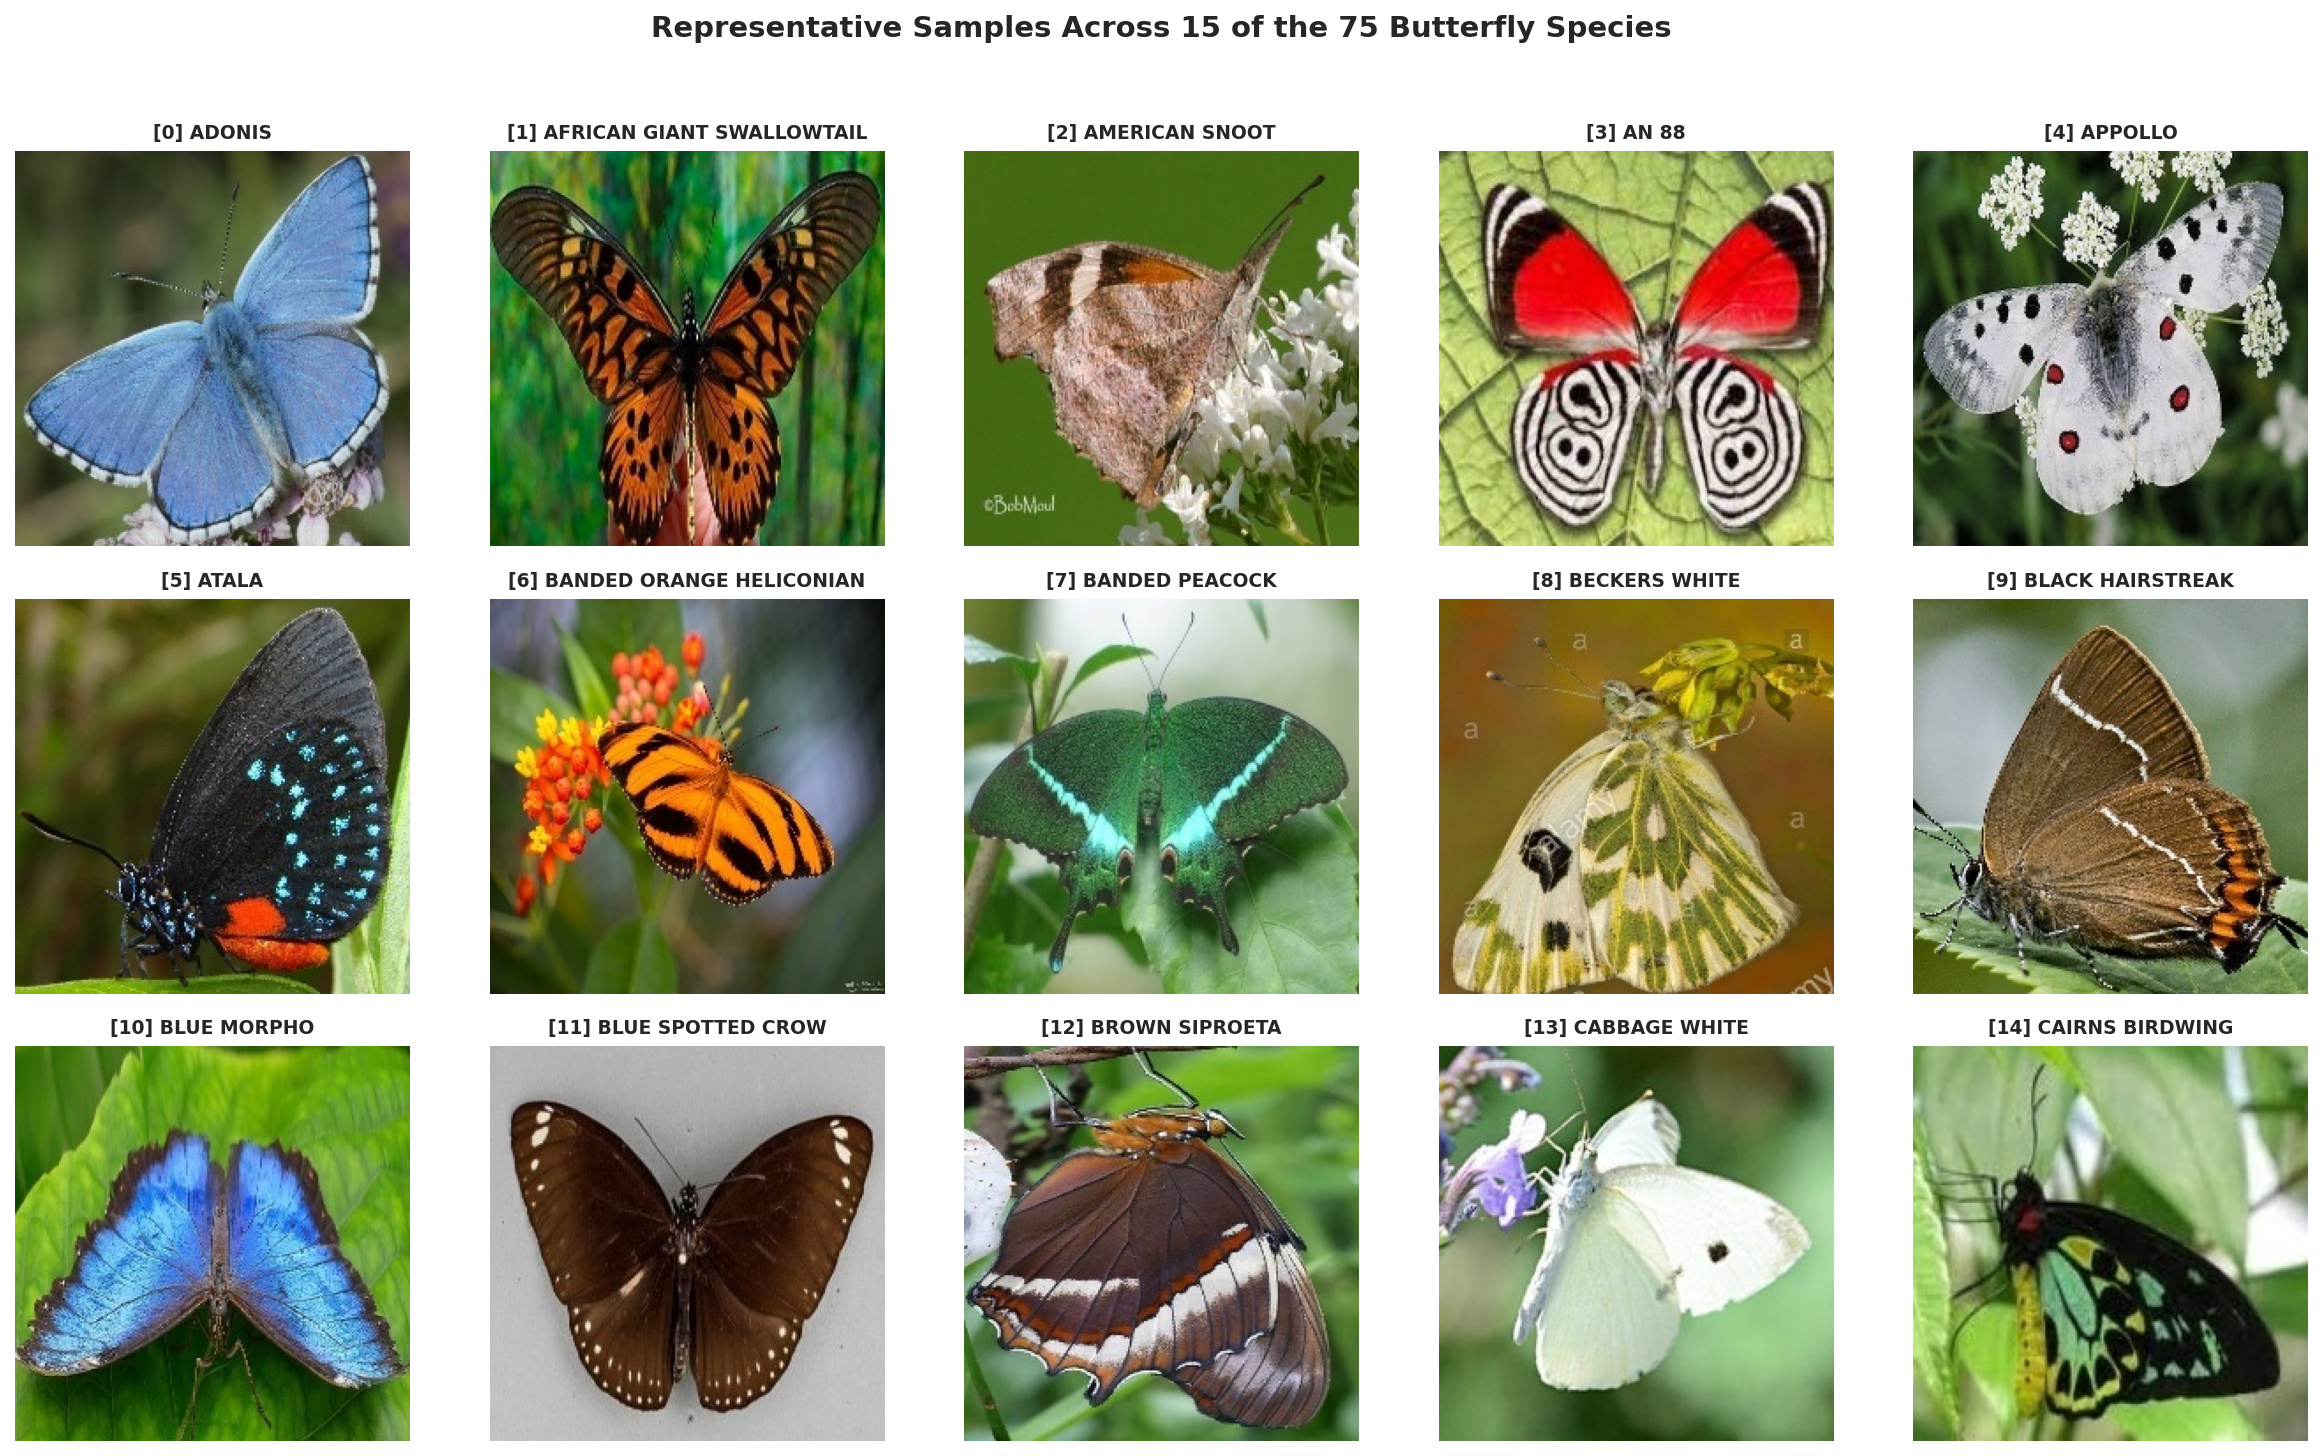

In [4]:
# Generates the following for EDA charts:
   # Summary of all 75 butterfly species
   # Plot 1: Distribution of class sizes across the species
   # Plot 2: Sample grid of species

# Summary of all 75 butterfly species
split_summary = (
    df_clean.groupby(["label", "class_name", "split"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)
split_summary["Total"] = split_summary[["train", "validation", "test"]].sum(axis=1)
split_summary = split_summary.sort_values("Total", ascending=False).reset_index(drop=True)
split_summary.to_csv(metadata_out_dir / "eda_class_split_summary.csv", index=False)

print("Summary results:\n")
display(split_summary.head(15))
print("\nImage Dimensions and Aspect Ratio Summary:\n")
display(df_clean[["verified_width", "verified_height", "verified_aspect_ratio"]].describe())
print("\n")

# Plot 1: Distribution of class sizes across the species
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

sns.histplot(split_summary["Total"], bins=15, kde=True, color="#2b5c8f", edgecolor="black", ax=axes[0])
axes[0].axvline(split_summary["Total"].mean(), color="red", linestyle="--", label=f"Mean ({split_summary['Total'].mean():.1f} imgs/class)")
axes[0].set_title("Distribution of Image Counts Across All 75 Species", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Images per Species Class")
axes[0].set_ylabel("Number of Species")
axes[0].legend()

top20_df = split_summary.head(20).set_index("class_name")[["train", "validation", "test"]]
top20_df.plot(
    kind="barh",
    stacked=True,
    color=["#2b5c8f", "#38a3a5", "#f4a261"],
    edgecolor="black",
    ax=axes[1],
)
axes[1].invert_yaxis()
axes[1].set_title("Top 20 Butterfly Species by Stratified Split Count", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Number of Images")
axes[1].set_ylabel("Butterfly Species")
axes[1].legend(title="Split", loc="lower right")

plt.tight_layout()
plt.savefig(plots_dir / "fig1_class_distribution_by_split.png", dpi=300)
plt.show()
print("\n")

# Plot 2: Sample grid of species
sample_species_df = df_clean.sort_values("label").drop_duplicates("label").head(15)

fig, axes = plt.subplots(3, 5, figsize=(16, 9.5))
axes_flat = axes.flatten()
for ax in axes_flat:
    ax.axis("off")

for ax, (_, row) in zip(axes_flat, sample_species_df.iterrows()):
    with Image.open(row["local_full_path"]) as img:
        img_square = ImageOps.fit(ImageOps.exif_transpose(img).convert("RGB"), (224, 224))
    ax.imshow(img_square)
    ax.set_title(f"[{row['label']}] {row['class_name']}", fontsize=9, fontweight="bold")

plt.suptitle("Representative Samples Across 15 of the 75 Butterfly Species", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(plots_dir / "fig3_species_sample_grid.png", dpi=300, bbox_inches="tight")
plt.show()

## Feature Variable Definition, Refinement, and Feature Engineering


CV Feature Engineering:   0%|          | 0/6495 [00:00<?, ?it/s]


Computed Empirical Training Set RGB Mean: [0.4814, 0.4661, 0.3372]
Computed Empirical Training Set RGB Std:  [0.2689, 0.2589, 0.2669]


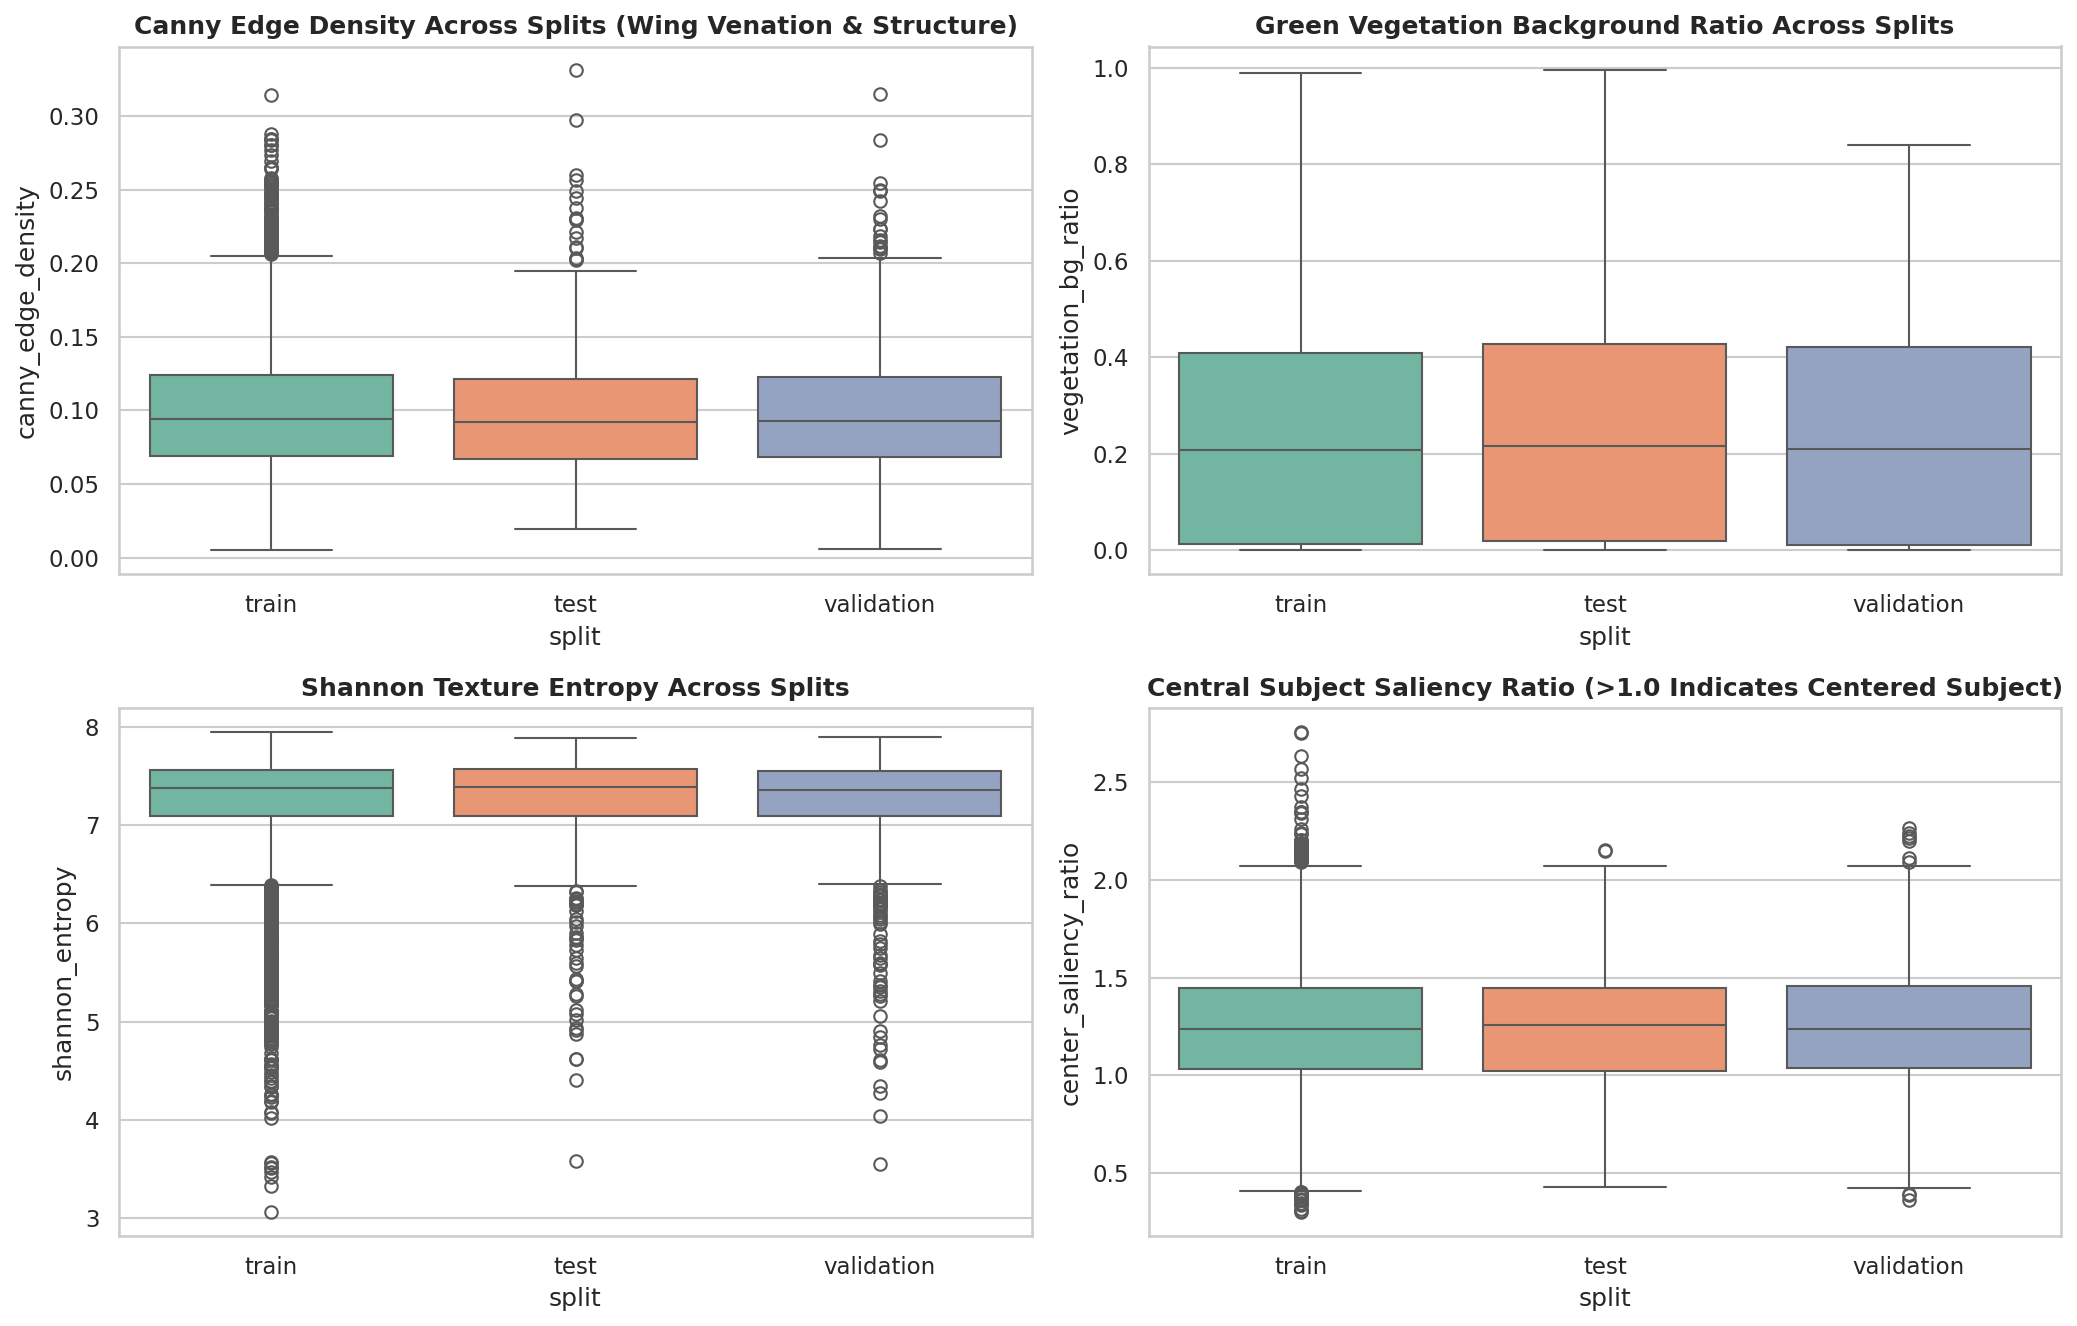

In [5]:
# Extracts quant feature variables per image in a single loop
eval_size = (256, 256)
feature_rows = []

for idx, row in tqdm(df_clean.iterrows(), total=len(df_clean), desc="CV Feature Engineering"):
    img_path = row["local_full_path"]
    with Image.open(img_path) as pil_img:
        pil_img = ImageOps.exif_transpose(pil_img).convert("RGB")
        pil_resized = pil_img.resize(eval_size, Image.Resampling.BILINEAR)
        rgb_arr = np.asarray(pil_resized, dtype=np.uint8)

    # Normalize RGB to [0, 1]
    rgb_norm = rgb_arr.astype(np.float32) / 255.0
    r_mean, g_mean, b_mean = rgb_norm.mean(axis=(0, 1))
    r_std, g_std, b_std = rgb_norm.std(axis=(0, 1))

    # Convert to HSV and Grayscale in OpenCV
    hsv_arr = cv2.cvtColor(rgb_arr, cv2.COLOR_RGB2HSV)
    gray_arr = cv2.cvtColor(rgb_arr, cv2.COLOR_RGB2GRAY)

    h_mean, s_mean, v_mean = hsv_arr.mean(axis=(0, 1))

    # Green vegetation background ratio
    veg_mask = cv2.inRange(hsv_arr, np.array([35, 40, 40]), np.array([85, 255, 255]))
    vegetation_ratio = float(np.count_nonzero(veg_mask)) / float(veg_mask.size)

    # Edge density to captures wing venation & structural boundaries
    edges = cv2.Canny(gray_arr, threshold1=100, threshold2=200)
    edge_density = float(np.count_nonzero(edges)) / float(edges.size)

    # Sobel gradient magnitude
    sobel_x = cv2.Sobel(gray_arr, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(gray_arr, cv2.CV_64F, 0, 1, ksize=3)
    grad_mag = np.hypot(sobel_x, sobel_y)
    mean_gradient = float(np.mean(grad_mag))

    h, w = gray_arr.shape
    center_grad_energy = float(np.mean(grad_mag[h // 4:3 * h // 4, w // 4:3 * w // 4]))
    center_saliency_ratio = center_grad_energy / max(mean_gradient, 1e-6)

    # Laplacian variance
    laplacian_var = float(cv2.Laplacian(gray_arr, cv2.CV_64F).var())

    # Texture entropy
    hist = cv2.calcHist([gray_arr], [0], None, [256], [0, 256]).ravel()
    prob = hist / max(hist.sum(), 1.0)
    prob = prob[prob > 0]
    shannon_entropy = float(-np.sum(prob * np.log2(prob)))

    # RMS contrast
    rms_contrast = float(np.std(gray_arr.astype(np.float32) / 255.0))

    feature_rows.append({
        "r_mean": round(float(r_mean), 5),
        "g_mean": round(float(g_mean), 5),
        "b_mean": round(float(b_mean), 5),
        "r_std": round(float(r_std), 5),
        "g_std": round(float(g_std), 5),
        "b_std": round(float(b_std), 5),
        "hsv_h_mean": round(float(h_mean), 3),
        "hsv_s_mean": round(float(s_mean), 3),
        "hsv_v_mean": round(float(v_mean), 3),
        "vegetation_bg_ratio": round(vegetation_ratio, 4),
        "canny_edge_density": round(edge_density, 4),
        "sobel_grad_mean": round(mean_gradient, 3),
        "center_saliency_ratio": round(center_saliency_ratio, 4),
        "laplacian_sharpness": round(laplacian_var, 2),
        "shannon_entropy": round(shannon_entropy, 4),
        "rms_contrast": round(rms_contrast, 4),
    })

df_features = pd.DataFrame(feature_rows)
df_enriched = pd.concat([df_clean.reset_index(drop=True), df_features], axis=1)

# Compute mean and Std on the training split
train_subset = df_enriched[df_enriched["split"] == "train"]
dataset_rgb_mean = [
    round(float(train_subset["r_mean"].mean()), 4),
    round(float(train_subset["g_mean"].mean()), 4),
    round(float(train_subset["b_mean"].mean()), 4),
]
dataset_rgb_std = [
    round(float(np.sqrt((train_subset["r_std"] ** 2).mean() + train_subset["r_mean"].var())), 4),
    round(float(np.sqrt((train_subset["g_std"] ** 2).mean() + train_subset["g_mean"].var())), 4),
    round(float(np.sqrt((train_subset["b_std"] ** 2).mean() + train_subset["b_mean"].var())), 4),
]

print(f"\nComputed Empirical Training Set RGB Mean: {dataset_rgb_mean}")
print(f"Computed Empirical Training Set RGB Std:  {dataset_rgb_std}")

# Plot distributions across splits
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.boxplot(data=df_enriched, x="split", y="canny_edge_density", palette="Set2", ax=axes[0, 0])
axes[0, 0].set_title("Canny Edge Density Across Splits (Wing Venation & Structure)", fontweight="bold")

sns.boxplot(data=df_enriched, x="split", y="vegetation_bg_ratio", palette="Set2", ax=axes[0, 1])
axes[0, 1].set_title("Green Vegetation Background Ratio Across Splits", fontweight="bold")

sns.boxplot(data=df_enriched, x="split", y="shannon_entropy", palette="Set2", ax=axes[1, 0])
axes[1, 0].set_title("Shannon Texture Entropy Across Splits", fontweight="bold")

sns.boxplot(data=df_enriched, x="split", y="center_saliency_ratio", palette="Set2", ax=axes[1, 1])
axes[1, 1].set_title("Central Subject Saliency Ratio (>1.0 Indicates Centered Subject)", fontweight="bold")

plt.tight_layout()
plt.savefig(plots_dir / "fig4_engineered_cv_features_distribution.png", dpi=300)
plt.show()

## Image Pre-Processing


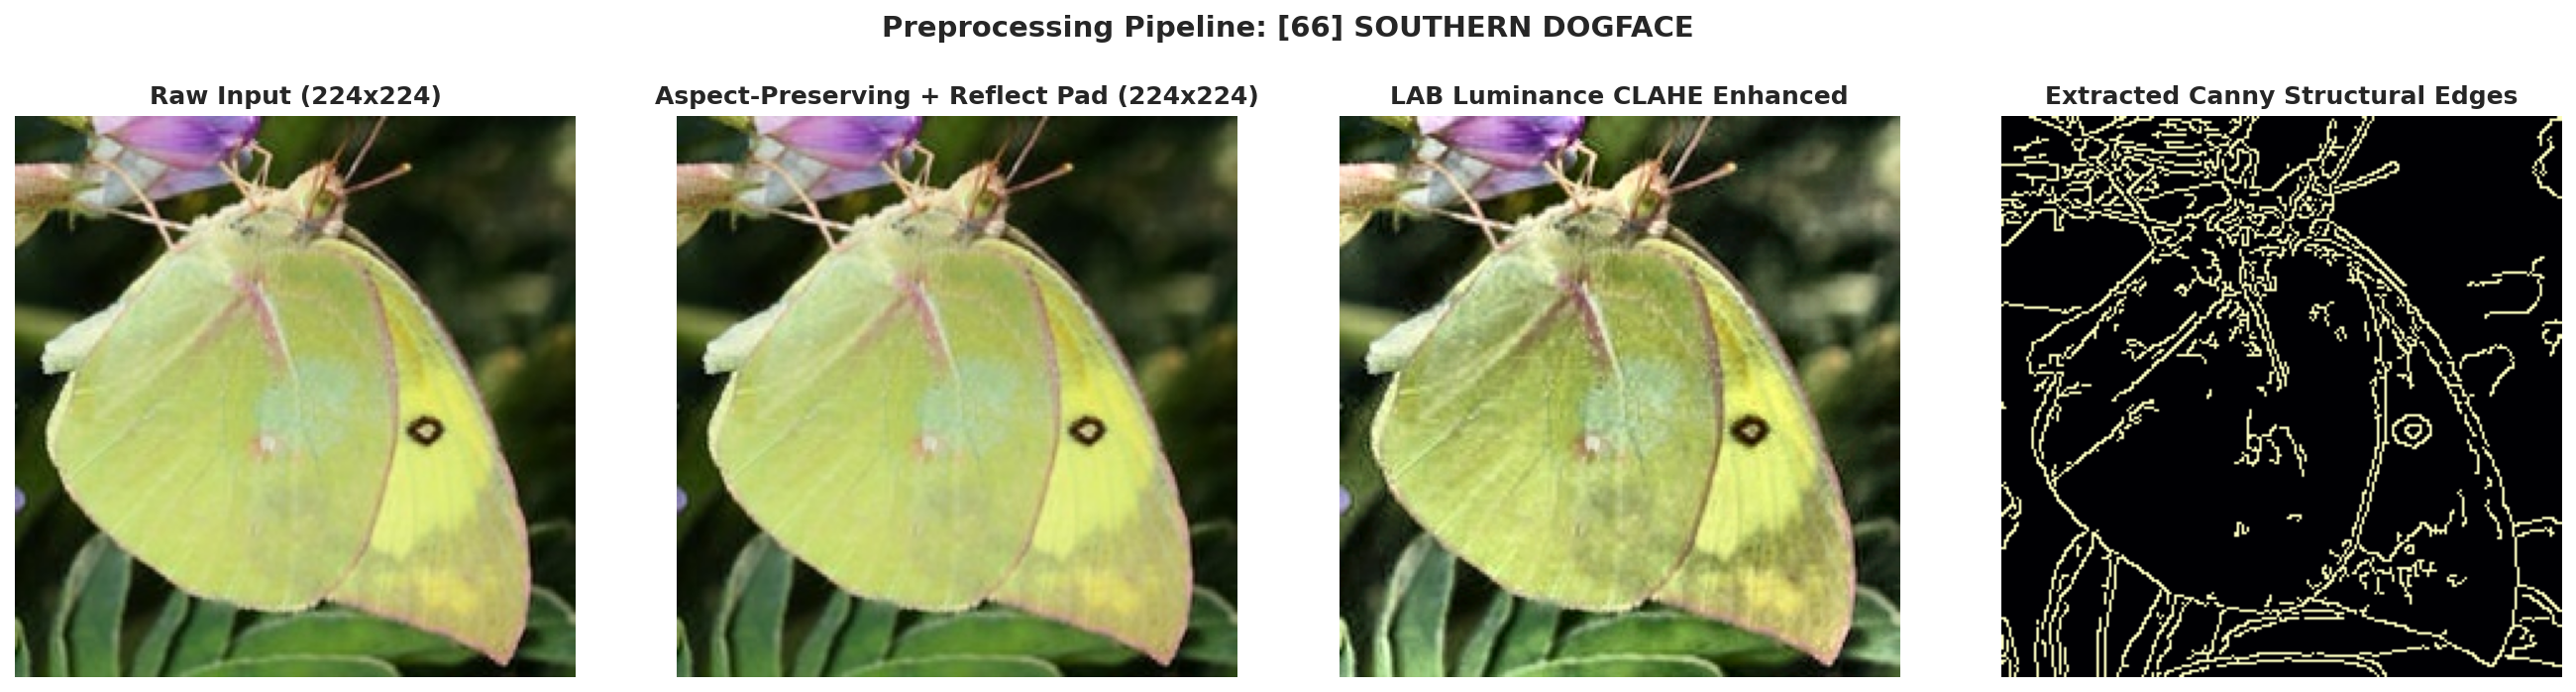

Preprocessing Images:   0%|          | 0/6495 [00:00<?, ?it/s]


All Preprocessed Images and Enriched Feature Tables Exported to Google Drive:
  ImageFolder Directory: /content/drive/MyDrive/Colab Notebooks/AAI521_Pollinator_Project/preprocessed_data
  Fast Tar.Gz Archive  : /content/drive/MyDrive/Colab Notebooks/AAI521_Pollinator_Project/pollinator_preprocessed_224x224_archive.tar.gz
  Enriched Master CSV  : /content/drive/MyDrive/Colab Notebooks/AAI521_Pollinator_Project/processed_metadata/pollinator_preprocessed_features_master.csv
  Pipeline Manifest    : /content/drive/MyDrive/Colab Notebooks/AAI521_Pollinator_Project/processed_metadata/preprocessing_manifest.json


In [6]:
target_size = 224

def preprocess_pollinator_image(
    img_path: str,
    target_size: int = target_size,
    apply_clahe: bool = True,
) -> np.ndarray:
    """Resizes image preserving aspect ratio with reflection padding and applies LAB"""
    with Image.open(img_path) as pil_img:
        pil_img = ImageOps.exif_transpose(pil_img).convert("RGB")
        rgb = np.asarray(pil_img, dtype=np.uint8)

    orig_h, orig_w = rgb.shape[:2]
    scale = target_size / float(max(orig_h, orig_w))
    new_w = max(1, int(round(orig_w * scale)))
    new_h = max(1, int(round(orig_h * scale)))

    interp = cv2.INTER_AREA if scale < 1.0 else cv2.INTER_CUBIC
    resized = cv2.resize(rgb, (new_w, new_h), interpolation=interp)

    pad_top = (target_size - new_h) // 2
    pad_bottom = target_size - new_h - pad_top
    pad_left = (target_size - new_w) // 2
    pad_right = target_size - new_w - pad_left

    padded = cv2.copyMakeBorder(
        resized, pad_top, pad_bottom, pad_left, pad_right, borderType=cv2.BORDER_REFLECT_101
    )

    if apply_clahe:
        lab = cv2.cvtColor(padded, cv2.COLOR_RGB2LAB)
        l_chan, a_chan, b_chan = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        l_enhanced = clahe.apply(l_chan)
        output_rgb = cv2.cvtColor(cv2.merge((l_enhanced, a_chan, b_chan)), cv2.COLOR_LAB2RGB)
    else:
        output_rgb = padded

    return output_rgb

# Show preprocessing pipeline steps
sample_row = df_enriched.iloc[0]
with Image.open(sample_row["local_full_path"]) as raw_pil:
    raw_rgb = np.asarray(ImageOps.exif_transpose(raw_pil).convert("RGB"))

padded_only_rgb = preprocess_pollinator_image(
    sample_row["local_full_path"], target_size=target_size, apply_clahe=False
)
clahe_rgb = preprocess_pollinator_image(
    sample_row["local_full_path"], target_size=target_size, apply_clahe=True
)
edges_demo = cv2.Canny(cv2.cvtColor(clahe_rgb, cv2.COLOR_RGB2GRAY), 100, 200)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
axes[0].imshow(raw_rgb)
axes[0].set_title(f"Raw Input ({raw_rgb.shape[1]}x{raw_rgb.shape[0]})", fontweight="bold")
axes[1].imshow(padded_only_rgb)
axes[1].set_title(f"Aspect-Preserving + Reflect Pad ({target_size}x{target_size})", fontweight="bold")
axes[2].imshow(clahe_rgb)
axes[2].set_title("LAB Luminance CLAHE Enhanced", fontweight="bold")
axes[3].imshow(edges_demo, cmap="magma")
axes[3].set_title("Extracted Canny Structural Edges", fontweight="bold")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"Preprocessing Pipeline: [{sample_row['label']}] {sample_row.get('common_name', sample_row['class_name'])}",
    fontsize=14,
    fontweight="bold",
    y=1.03,
)
plt.tight_layout()
plt.savefig(plots_dir / "fig5_preprocessing_pipeline_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# Preprocess and stage locally, then archive to google drive
local_preprocessed_stage = Path("/content/preprocessed_pollinator_224")
if local_preprocessed_stage.exists():
    shutil.rmtree(local_preprocessed_stage)
local_preprocessed_stage.mkdir(parents=True, exist_ok=True)

stage_paths = []
drive_paths = []
clahe_train_means = []
clahe_train_stds = []

for idx, row in tqdm(df_enriched.iterrows(), total=len(df_enriched), desc="Preprocessing Images"):
    split_name = row["split"]
    label_id = int(row["label"])
    safe_class_name = str(row["class_name"]).replace(" ", "_").replace("/", "_")
    class_folder_name = f"{label_id:02d}_{safe_class_name}"

    stage_class_dir = local_preprocessed_stage / split_name / class_folder_name
    stage_class_dir.mkdir(parents=True, exist_ok=True)

    drive_class_dir = preprocessed_dir / split_name / class_folder_name

    out_filename = f"{row['image_id']}.jpg"
    stage_file_path = stage_class_dir / out_filename
    drive_file_path = drive_class_dir / out_filename

    processed_rgb = preprocess_pollinator_image(
        row["local_full_path"], target_size=target_size, apply_clahe=True
    )

    if split_name == "train":
        norm_proc = processed_rgb.astype(np.float32) / 255.0
        clahe_train_means.append(norm_proc.mean(axis=(0, 1)))
        clahe_train_stds.append(norm_proc.std(axis=(0, 1)))

    Image.fromarray(processed_rgb).save(stage_file_path, format="JPEG", quality=95)

    stage_paths.append(str(stage_file_path))
    drive_paths.append(str(drive_file_path))

# Update dataset_rgb_mean and dataset_rgb_std to reflect CLAHE-preprocessed training images
clahe_means_arr = np.array(clahe_train_means)
clahe_stds_arr = np.array(clahe_train_stds)
dataset_rgb_mean = [round(float(x), 4) for x in clahe_means_arr.mean(axis=0)]
dataset_rgb_std = [
    round(float(x), 4)
    for x in np.sqrt((clahe_stds_arr ** 2).mean(axis=0) + clahe_means_arr.var(axis=0))
]

df_enriched["preprocessed_local_path"] = stage_paths
df_enriched["preprocessed_drive_path"] = drive_paths

# Save enriched metadata & feature matrices to drive
enriched_csv_path = metadata_out_dir / "pollinator_preprocessed_features_master.csv"
enriched_parquet_path = metadata_out_dir / "pollinator_preprocessed_features_master.parquet"

df_enriched.to_csv(enriched_csv_path, index=False)
df_enriched.to_parquet(enriched_parquet_path, index=False)

for split_name in ["train", "validation", "test"]:
    split_df = df_enriched[df_enriched["split"] == split_name]
    split_df.to_csv(metadata_out_dir / f"{split_name}_preprocessed_features.csv", index=False)

# Package a fast-loading compressed tarball of all preprocessed images on Google Drive
archive_base = drive_project_root / "pollinator_preprocessed_224x224_archive"
shutil.make_archive(str(archive_base), "gztar", root_dir=local_preprocessed_stage)

# Save Normalization & Pipeline Configuration Manifest JSON for Step 3 Teammates
pipeline_manifest = {
    "dataset_source": kaggle_dataset_id,
    "total_verified_images": int(len(df_enriched)),
    "num_classes": int(df_enriched["label"].nunique()),
    "image_resolution": [target_size, target_size, 3],
    "clahe_applied": True,
    "train_rgb_mean": dataset_rgb_mean,
    "train_rgb_std": dataset_rgb_std,
    "imagenet_rgb_mean": [0.485, 0.456, 0.406],
    "imagenet_rgb_std": [0.229, 0.224, 0.225],
    "splits": df_enriched["split"].value_counts().to_dict(),
    "engineered_feature_columns": list(df_features.columns),
    "drive_preprocessed_root": str(preprocessed_dir),
    "drive_archive_path": f"{archive_base}.tar.gz",
    "drive_master_csv": str(enriched_csv_path),
}
with open(metadata_out_dir / "preprocessing_manifest.json", "w", encoding="utf-8") as f:
    json.dump(pipeline_manifest, f, indent=4)

print("\nAll Preprocessed Images and Enriched Feature Tables Exported to Google Drive:")
print(f"  ImageFolder Directory: {preprocessed_dir}")
print(f"  Fast Tar.Gz Archive  : {archive_base}.tar.gz")
print(f"  Enriched Master CSV  : {enriched_csv_path}")
print(f"  Pipeline Manifest    : {metadata_out_dir / 'preprocessing_manifest.json'}")

## PyTorch Multi-Modal Dataset, Dynamic Augmentation & DataLoader Verification

In [7]:
engineered_feature_cols = list(df_features.columns)

# Compute z-score standardization statistics on training tabular features only
train_feat_mean = df_enriched[df_enriched["split"] == "train"][engineered_feature_cols].mean().values
train_feat_std = (
    df_enriched[df_enriched["split"] == "train"][engineered_feature_cols].std().values + 1e-7
)

def get_transforms(
    split: str,
    img_size: int = target_size,
    use_imagenet_norm: bool = False,
) -> A.Compose:
    """Returns albumentations transformation pipelines tailored to training vs eval splits.
    Set use_imagenet_norm=True when fine-tuning pretrained ImageNet backbones.
    """
    norm_mean = [0.485, 0.456, 0.406] if use_imagenet_norm else dataset_rgb_mean
    norm_std = [0.229, 0.224, 0.225] if use_imagenet_norm else dataset_rgb_std

    if split == "train":
        return A.Compose(
            [
                A.RandomResizedCrop(
                    size=(img_size, img_size), scale=(0.80, 1.0), ratio=(0.9, 1.1), p=0.8
                ),
                A.HorizontalFlip(p=0.5),
                A.VerticalFlip(p=0.2),
                A.Affine(scale=(0.9, 1.1), rotate=(-30, 30), translate_percent=(-0.05, 0.05), p=0.6),
                A.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.05, p=0.5),
                A.CoarseDropout(
                    num_holes_range=(1, 4),
                    hole_height_range=(12, 28),
                    hole_width_range=(12, 28),
                    fill=0,
                    p=0.3,
                ),
                A.Normalize(mean=norm_mean, std=norm_std),
                ToTensorV2(),
            ]
        )
    return A.Compose(
        [
            A.Resize(height=img_size, width=img_size),
            A.Normalize(mean=norm_mean, std=norm_std),
            ToTensorV2(),
        ]
    )

class PollinatorMultiModalDataset(Dataset):
    """Custom dataset with preprocessed RGB image tensors and engineered CV features"""

    def __init__(
        self,
        metadata_df: pd.DataFrame,
        transform: A.Compose = None,
        use_drive_paths: bool = False,
        is_train: bool = False,
        tabular_noise_std: float = 0.05,
    ) -> None:
        self.df = metadata_df.reset_index(drop=True)
        self.transform = transform
        self.use_drive_paths = use_drive_paths
        self.is_train = is_train
        self.tabular_noise_std = tabular_noise_std
        self.feature_matrix = (
            self.df[engineered_feature_cols].values.astype(np.float32) - train_feat_mean
        ) / train_feat_std

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, index: int) -> Dict[str, torch.Tensor]:
        row = self.df.iloc[index]
        img_path = (
            row["preprocessed_drive_path"]
            if self.use_drive_paths and Path(row["preprocessed_drive_path"]).exists()
            else row["preprocessed_local_path"]
        )

        with Image.open(img_path) as img:
            rgb_image = np.asarray(img.convert("RGB"), dtype=np.uint8)

        if self.transform is not None:
            tensor_img = self.transform(image=rgb_image)["image"]
        else:
            tensor_img = torch.from_numpy(rgb_image).permute(2, 0, 1).float() / 255.0

        tab_feat = torch.tensor(self.feature_matrix[index], dtype=torch.float32)
        if self.is_train and self.tabular_noise_std > 0:
            tab_feat = tab_feat + torch.randn_like(tab_feat) * self.tabular_noise_std

        return {
            "image": tensor_img,
            "tabular_features": tab_feat,
            "label": torch.tensor(int(row["label"]), dtype=torch.long),
            "image_id": str(row["image_id"]),
        }

batch_size = 32

train_dataset = PollinatorMultiModalDataset(
    df_enriched[df_enriched["split"] == "train"],
    transform=get_transforms("train"),
    use_drive_paths=False,
    is_train=True,
)
val_dataset = PollinatorMultiModalDataset(
    df_enriched[df_enriched["split"] == "validation"],
    transform=get_transforms("validation"),
    use_drive_paths=False,
    is_train=False,
)
test_dataset = PollinatorMultiModalDataset(
    df_enriched[df_enriched["split"] == "test"],
    transform=get_transforms("test"),
    use_drive_paths=False,
    is_train=False,
)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

sample_batch = next(iter(train_loader))
print(f"Train Batches: {len(train_loader)} | Val Batches: {len(val_loader)} | Test Batches: {len(test_loader)}")
print(f"Batch Image Tensor Shape            : {sample_batch['image'].shape} (B, C, H, W)")
print(f"Batch Engineered CV Features Shape  : {sample_batch['tabular_features'].shape} (B, N_features)")
print(f"Batch Target Label Tensor Shape     : {sample_batch['label'].shape} (B,)")
print(f"Image Tensor Value Range (Normed)   : [{sample_batch['image'].min():.2f}, {sample_batch['image'].max():.2f}]")

Train Batches: 163 | Val Batches: 21 | Test Batches: 21
Batch Image Tensor Shape            : torch.Size([32, 3, 224, 224]) (B, C, H, W)
Batch Engineered CV Features Shape  : torch.Size([32, 16]) (B, N_features)
Batch Target Label Tensor Shape     : torch.Size([32]) (B,)
Image Tensor Value Range (Normed)   : [-1.88, 2.31]
